# 💎 Jewelry Shop — Sales & Inventory Dashboard

Analysis of **`transactions.csv`** (simulated sales, Jan 2021 → Nov 2026) and **`inventory.csv`** (product catalog with stock levels).

**Sections:** KPIs · Sales trend · Product lines · Top products · Customers · Payments · Time patterns · Ratings · Inventory · Key insights

> Put both CSV files in the same folder as this notebook, then **Run All**. Use the filter cell below to focus on specific years or product lines, like a dashboard filter.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display, HTML

# ---------- look & feel ----------
PALETTE = ["#4C6EF5", "#12B886", "#F59F00", "#FA5252", "#7950F2", "#15AABF", "#E64980"]
sns.set_theme(style="whitegrid", palette=PALETTE, font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
money = mtick.FuncFormatter(lambda x, p: f"{x/1e6:.1f}M" if abs(x) >= 1e6 else f"{x/1e3:.0f}K" if abs(x) >= 1e3 else f"{x:.0f}")

# ---------- load data ----------
def find(name):
    for d in [Path("."), Path("/mnt/user-data/outputs")]:
        if (d / name).exists(): return d / name
    raise FileNotFoundError(f"{name} not found next to the notebook")

tx  = pd.read_csv(find("transactions.csv"))
inv = pd.read_csv(find("inventory.csv"))

tx["datetime"] = pd.to_datetime(tx["Date"] + " " + tx["Time"])
tx["Date"]     = pd.to_datetime(tx["Date"])
tx["Year"]     = tx["Date"].dt.year
tx["MonthNum"] = tx["Date"].dt.month
tx["YearMonth"]= tx["Date"].dt.to_period("M").dt.to_timestamp()
tx["Hour"]     = tx["datetime"].dt.hour
tx["Weekday"]  = tx["Date"].dt.day_name()
print(f"transactions: {len(tx):,} rows | {tx.Date.min():%d %b %Y} → {tx.Date.max():%d %b %Y}")
print(f"inventory   : {len(inv):,} products")

transactions: 24,000 rows | 01 Jan 2021 → 20 Nov 2026
inventory   : 581 products


## 🎛️ Dashboard filters
Set `None` for everything, or a list, e.g. `YEARS = [2025, 2026]`, `LINES = ["Rings", "Sets"]`.

In [2]:
YEARS = None      # e.g. [2024, 2025, 2026]
LINES = None      # e.g. ["Necklaces", "Rings"]

df = tx.copy()
if YEARS: df = df[df.Year.isin(YEARS)]
if LINES: df = df[df["Product Line"].isin(LINES)]
print(f"Filtered view: {len(df):,} transactions")

Filtered view: 24,000 transactions


## 1 · Key performance indicators

In [3]:
def kpi_cards(items):
    cards = "".join(f'''
      <div style="flex:1;min-width:150px;background:#fff;border:1px solid #e9ecef;border-left:5px solid {c};
                  border-radius:10px;padding:14px 16px;box-shadow:0 1px 3px rgba(0,0,0,.06);font-family:Arial,sans-serif">
        <div style="color:#868e96;font-size:12px;text-transform:uppercase;letter-spacing:.5px">{l}</div>
        <div style="color:#212529;font-size:24px;font-weight:700;margin-top:4px">{v}</div>
        <div style="color:#adb5bd;font-size:11px;margin-top:2px">{s}</div>
      </div>''' for (l, v, s, c) in items)
    display(HTML(f'<div style="display:flex;gap:12px;flex-wrap:wrap;margin:8px 0">{cards}</div>'))

revenue   = df["Total"].sum()
profit    = df["Gross Income"].sum()
subtotal  = df["Subtotal"].sum()
orders    = len(df)
units     = df["Quantity"].sum()
aov       = revenue / orders
margin    = profit / subtotal * 100
tax       = df["Tax 5%"].sum()
rating    = df["Rating"].mean()

kpi_cards([
    ("Total revenue",  f"{revenue/1e6:,.2f}M EGP", "incl. 5% tax",              PALETTE[0]),
    ("Gross profit",   f"{profit/1e6:,.2f}M EGP",  f"margin {margin:.1f}%",      PALETTE[1]),
    ("Orders",         f"{orders:,}",              f"{units:,} units sold",      PALETTE[2]),
    ("Avg order value",f"{aov:,.0f} EGP",          "per transaction",            PALETTE[4]),
    ("Tax collected",  f"{tax/1e3:,.0f}K EGP",     "5% VAT",                     PALETTE[3]),
    ("Avg rating",     f"{rating:.2f} / 10",       "customer satisfaction",      PALETTE[5]),
])
inv_cost   = inv["stock_value_cost"].sum(); inv_retail = inv["stock_value_retail"].sum()
kpi_cards([
    ("Products in catalog", f"{len(inv):,}", f"{inv.category.nunique()} categories", PALETTE[0]),
    ("Units in stock",      f"{inv.current_stock.sum():,}", "right now",             PALETTE[1]),
    ("Stock value (cost)",  f"{inv_cost/1e6:,.2f}M EGP",   "what it cost you",       PALETTE[2]),
    ("Stock value (retail)",f"{inv_retail/1e6:,.2f}M EGP", "potential sales value",  PALETTE[4]),
    ("Low-stock items",     f"{(inv.status=='Low stock').sum()}", "need reordering", PALETTE[3]),
])

## 2 · Sales trend

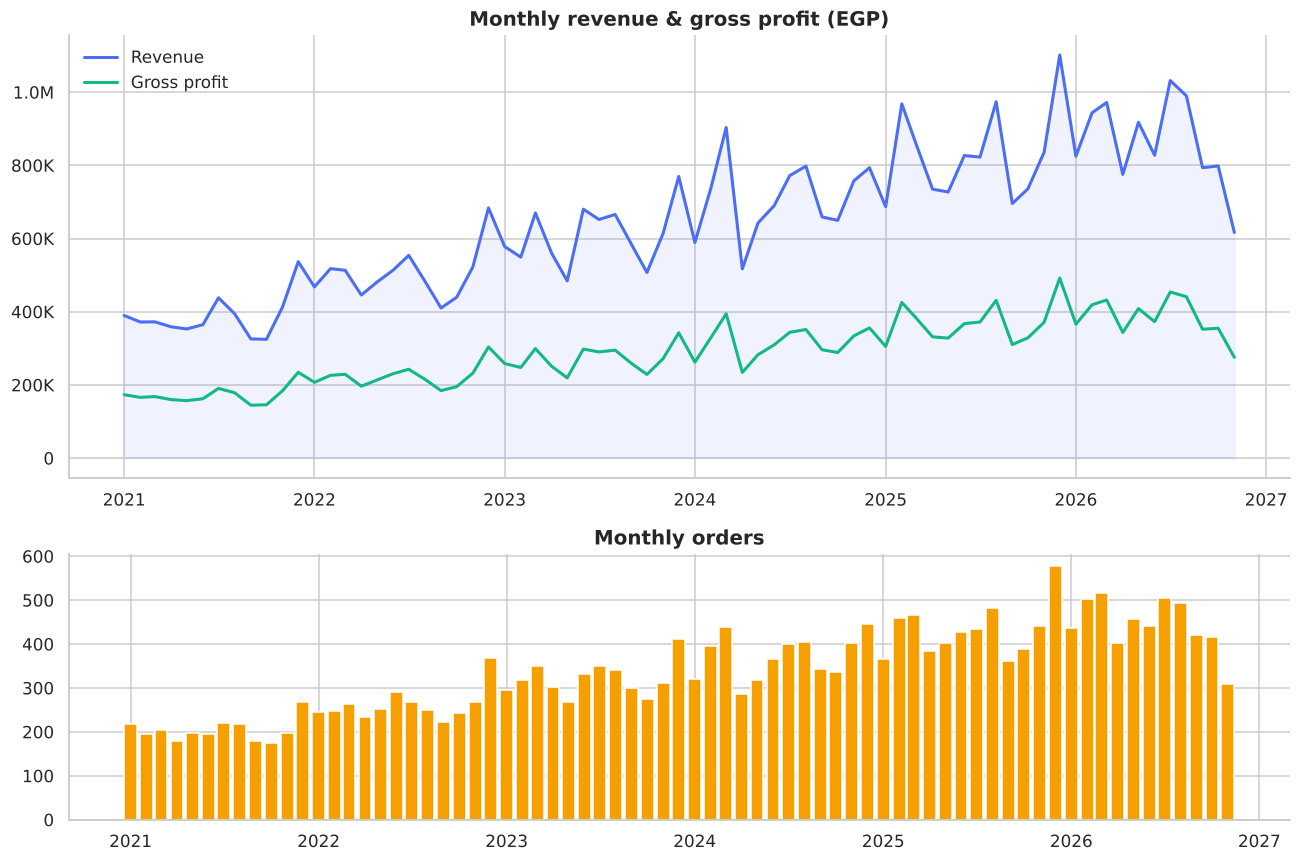

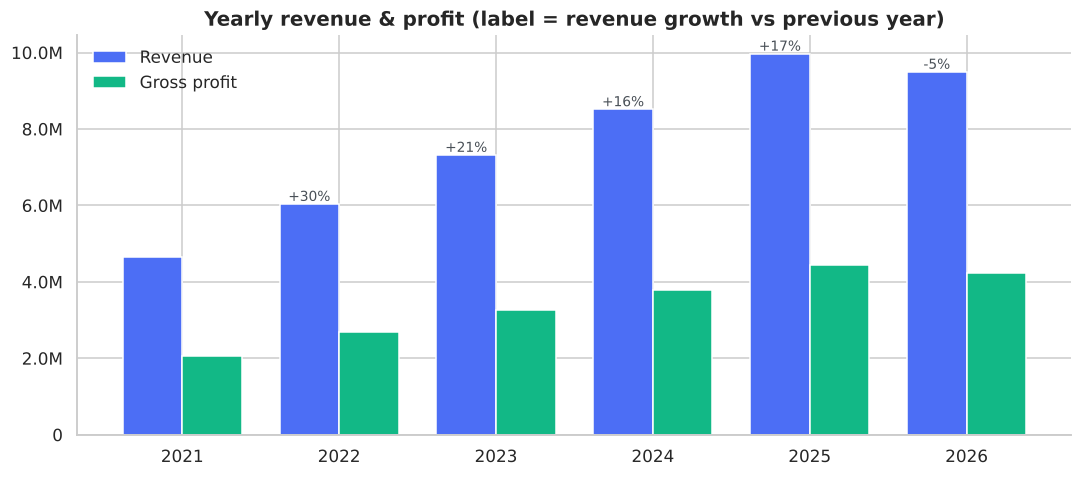

,Revenue,Profit,Orders,Growth %
Year,,,,
2021,"4,643,604","2,064,328","2,447",+nan%
2022,"6,032,544","2,676,281","3,152",+29.9%
2023,"7,315,623","3,260,491","3,853",+21.3%
2024,"8,510,586","3,781,765","4,456",+16.3%
2025,"9,964,920","4,444,295","5,192",+17.1%
2026,"9,490,803","4,219,153","4,900",-4.8%


In [4]:
monthly = df.groupby("YearMonth").agg(Revenue=("Total","sum"), Profit=("Gross Income","sum"), Orders=("Order No","count"))

fig, ax = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [2, 1.2]})
ax[0].plot(monthly.index, monthly.Revenue, color=PALETTE[0], lw=2, label="Revenue")
ax[0].plot(monthly.index, monthly.Profit,  color=PALETTE[1], lw=2, label="Gross profit")
ax[0].fill_between(monthly.index, monthly.Revenue, alpha=.08, color=PALETTE[0])
ax[0].yaxis.set_major_formatter(money); ax[0].set_title("Monthly revenue & gross profit (EGP)"); ax[0].legend(frameon=False)
ax[1].bar(monthly.index, monthly.Orders, width=25, color=PALETTE[2])
ax[1].set_title("Monthly orders"); plt.tight_layout(); plt.show()

yearly = df.groupby("Year").agg(Revenue=("Total","sum"), Profit=("Gross Income","sum"), Orders=("Order No","count"))
yearly["Growth %"] = yearly.Revenue.pct_change() * 100
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(yearly)); w = .38
ax.bar(x - w/2, yearly.Revenue, w, label="Revenue", color=PALETTE[0])
ax.bar(x + w/2, yearly.Profit,  w, label="Gross profit", color=PALETTE[1])
ax.set_xticks(x); ax.set_xticklabels(yearly.index); ax.yaxis.set_major_formatter(money)
for i, g in enumerate(yearly["Growth %"]):
    if pd.notna(g): ax.text(i - w/2, yearly.Revenue.iloc[i], f"{g:+.0f}%", ha="center", va="bottom", fontsize=9, color="#495057")
ax.set_title("Yearly revenue & profit (label = revenue growth vs previous year)"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
display(yearly.style.format({"Revenue":"{:,.0f}","Profit":"{:,.0f}","Orders":"{:,}","Growth %":"{:+.1f}%"}))

## 3 · Product lines

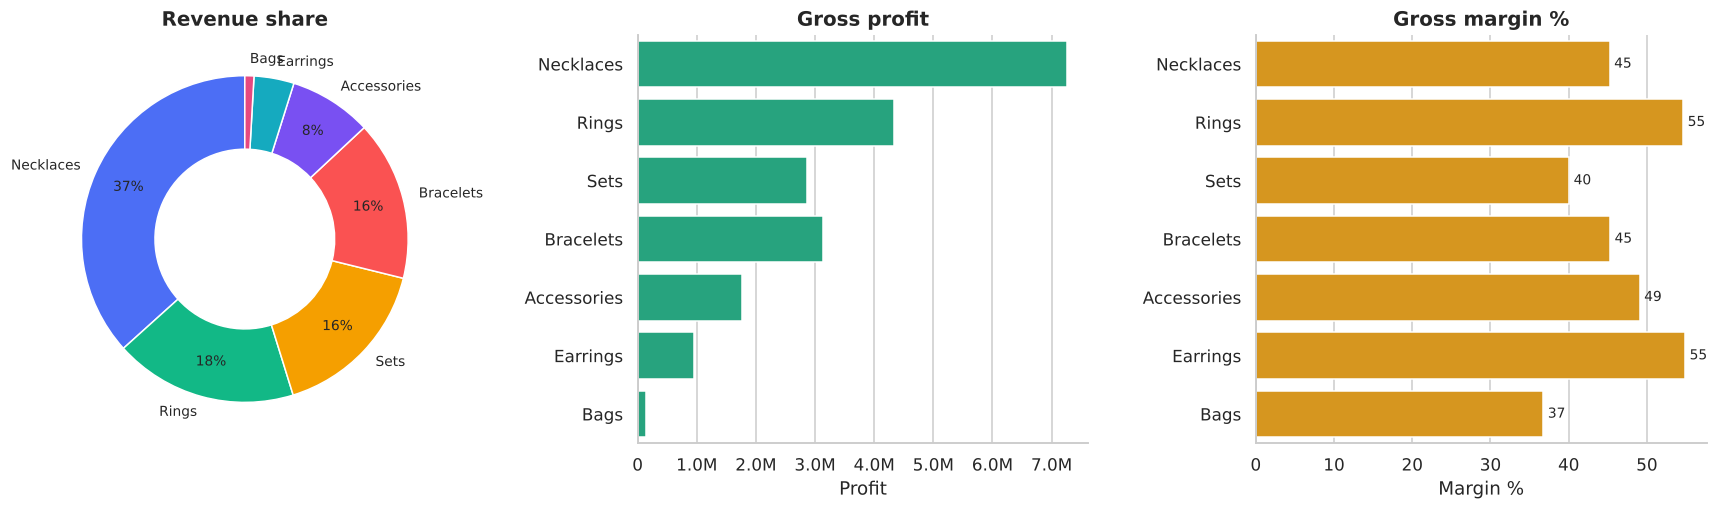

,Revenue,Profit,Units,Orders,Margin %
Product Line,,,,,
Necklaces,"16,850,757","7,258,543","10,421","8,281",45.2%
Rings,"8,326,668","4,332,142","11,662","7,254",54.6%
Sets,"7,516,152","2,866,836","1,657","1,307",40.0%
Bracelets,"7,269,066","3,134,903","3,722","3,008",45.3%
Accessories,"3,763,200","1,758,516","3,584","2,247",49.1%
Earrings,"1,819,272","950,830","2,548","1,632",54.9%
Bags,"412,965","144,544",437,271,36.8%


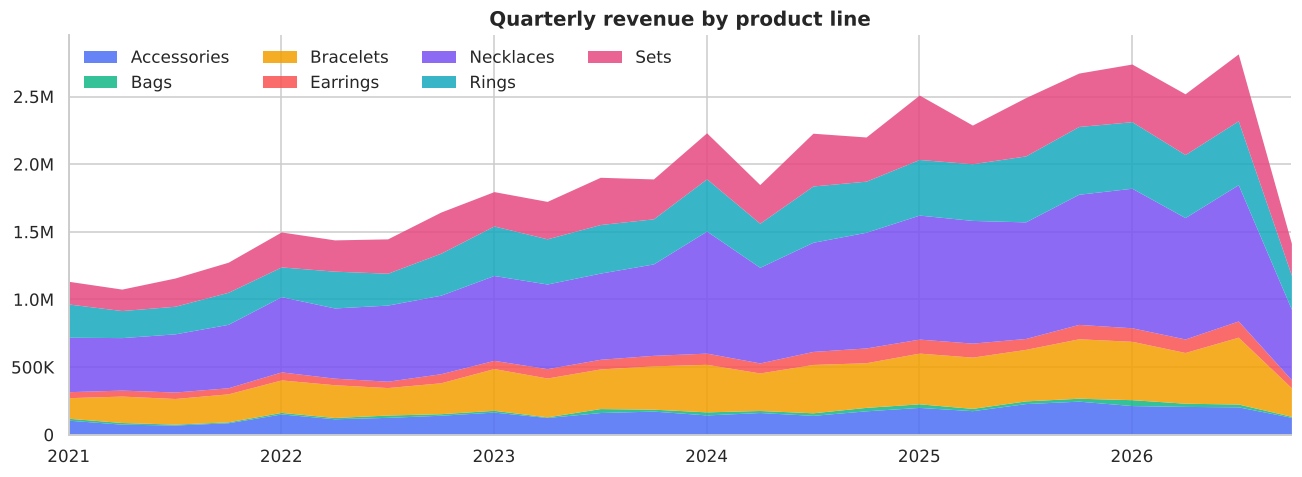

In [5]:
pl = df.groupby("Product Line").agg(Revenue=("Total","sum"), Profit=("Gross Income","sum"),
                                    Subtotal=("Subtotal","sum"), Units=("Quantity","sum"), Orders=("Order No","count"))
pl["Margin %"] = pl.Profit / pl.Subtotal * 100
pl = pl.sort_values("Revenue", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].pie(pl.Revenue, labels=pl.index, autopct=lambda v: f"{v:.0f}%" if v >= 5 else "", startangle=90, colors=PALETTE,
          wedgeprops=dict(width=.45, edgecolor="white"), pctdistance=.78, textprops={"fontsize": 9})
ax[0].set_title("Revenue share")
sns.barplot(x=pl.Profit, y=pl.index, ax=ax[1], color=PALETTE[1]); ax[1].xaxis.set_major_formatter(money); ax[1].set_title("Gross profit"); ax[1].set_ylabel("")
sns.barplot(x=pl["Margin %"], y=pl.index, ax=ax[2], color=PALETTE[2]); ax[2].set_title("Gross margin %"); ax[2].set_ylabel("")
for a in ax[2:]: 
    for c in a.containers: a.bar_label(c, fmt="%.0f", padding=3, fontsize=9)
plt.tight_layout(); plt.show()
display(pl.drop(columns="Subtotal").style.format({"Revenue":"{:,.0f}","Profit":"{:,.0f}","Units":"{:,}","Orders":"{:,}","Margin %":"{:.1f}%"})
        .background_gradient(subset=["Revenue"], cmap="Blues"))

mix = df.pivot_table(index="YearMonth", columns="Product Line", values="Total", aggfunc="sum").fillna(0)
mix.resample("QS").sum().plot.area(figsize=(12, 4.5), color=PALETTE, alpha=.85, linewidth=0)
plt.gca().yaxis.set_major_formatter(money); plt.title("Quarterly revenue by product line"); plt.xlabel("")
plt.legend(frameon=False, ncol=4, loc="upper left"); plt.tight_layout(); plt.show()

## 4 · Top & bottom products

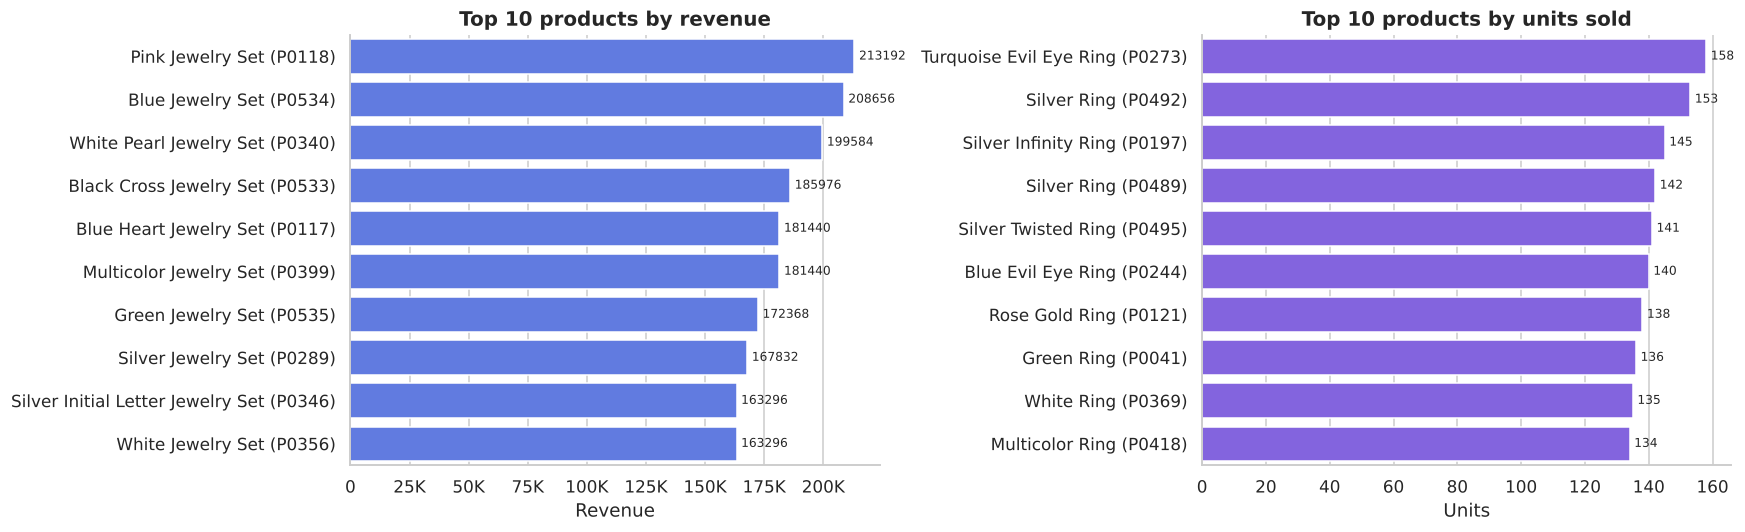

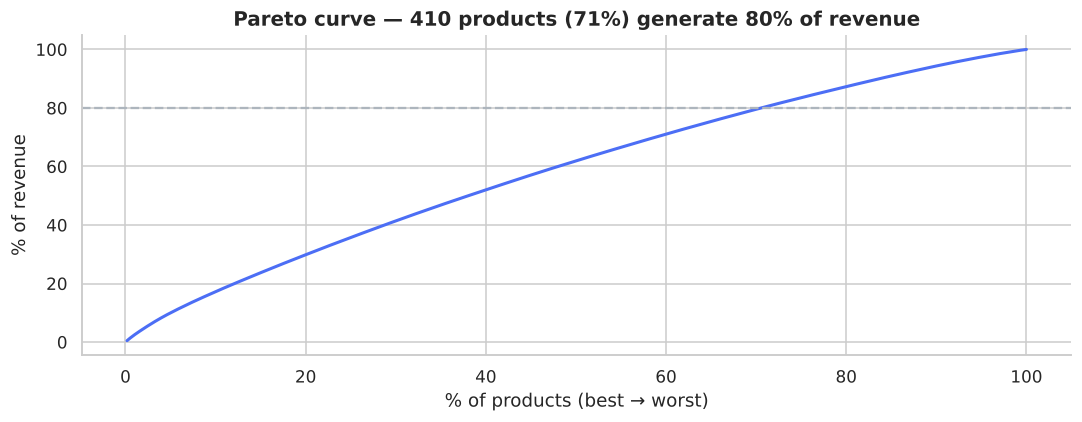

Product ID,Product Name,Product Line,Units,Revenue
P0466,Blue Infinity Bracelet,Bracelets,17,"33,201"
P0518,Rose Gold Star Bracelet,Bracelets,17,"33,201"
P0539,Silver Clutch Bag,Bags,36,"34,020"
P0477,Silver Snake Ring,Rings,52,"37,128"
P0284,Pink Bow Necklace,Necklaces,23,"37,191"
P0123,White Accessory,Accessories,36,"37,800"
P0250,Silver Bow Necklace,Necklaces,24,"38,808"
P0392,Black Evil Eye Necklace,Necklaces,24,"38,808"
P0046,Turquoise Ring,Rings,55,"39,270"
P0461,Black Earrings,Earrings,55,"39,270"


In [6]:
prod = df.groupby(["Product ID","Product Name","Product Line"]).agg(Revenue=("Total","sum"), Units=("Quantity","sum"), Profit=("Gross Income","sum")).reset_index()
prod["Label"] = prod["Product Name"] + " (" + prod["Product ID"] + ")"
top_rev, top_units = prod.nlargest(10, "Revenue"), prod.nlargest(10, "Units")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=top_rev,   x="Revenue", y="Label", ax=ax[0], color=PALETTE[0]); ax[0].set_title("Top 10 products by revenue")
sns.barplot(data=top_units, x="Units",   y="Label", ax=ax[1], color=PALETTE[4]); ax[1].set_title("Top 10 products by units sold")
ax[0].xaxis.set_major_formatter(money)
for a in ax: a.set_ylabel(""); [a.bar_label(c, fmt="%.0f", padding=3, fontsize=8) for c in a.containers]
plt.tight_layout(); plt.show()

# Pareto: how concentrated is revenue?
p = prod.sort_values("Revenue", ascending=False).reset_index(drop=True)
p["cum_share"] = p.Revenue.cumsum() / p.Revenue.sum() * 100
n80 = (p.cum_share <= 80).sum() + 1
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(1, len(p)+1) / len(p) * 100, p.cum_share, color=PALETTE[0], lw=2)
ax.axhline(80, ls="--", color="#adb5bd"); ax.set_xlabel("% of products (best → worst)"); ax.set_ylabel("% of revenue")
ax.set_title(f"Pareto curve — {n80} products ({n80/len(p):.0%}) generate 80% of revenue"); plt.tight_layout(); plt.show()

display(HTML("<b>Bottom 10 sellers (that sold at least once)</b>"))
display(prod.nsmallest(10, "Revenue")[["Product ID","Product Name","Product Line","Units","Revenue"]].style.format({"Revenue":"{:,.0f}"}).hide(axis="index"))

## 5 · Customers

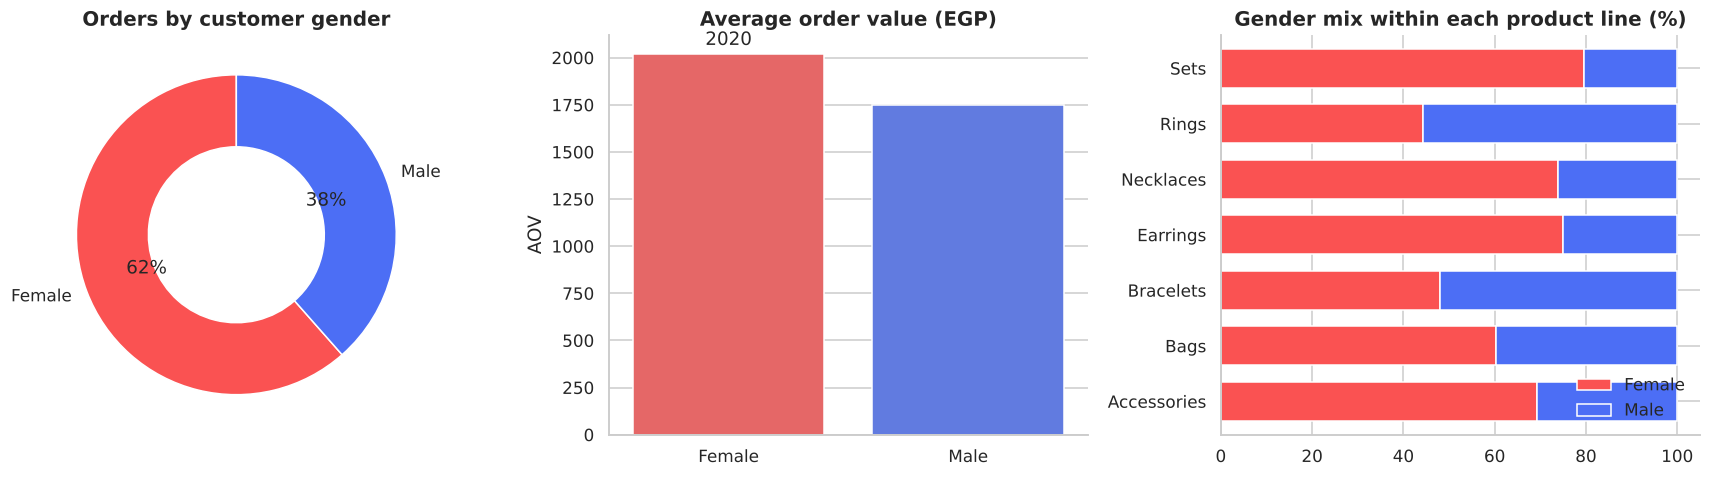

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
g = df.groupby("Gender").agg(Revenue=("Total","sum"), Orders=("Order No","count"), AOV=("Total","mean"))
ax[0].pie(g.Orders, labels=g.index, autopct="%1.0f%%", colors=[PALETTE[3], PALETTE[0]], startangle=90, wedgeprops=dict(width=.45, edgecolor="white"))
ax[0].set_title("Orders by customer gender")
sns.barplot(x=g.index, y=g.AOV, ax=ax[1], palette=[PALETTE[3], PALETTE[0]]); ax[1].set_title("Average order value (EGP)"); ax[1].set_xlabel("")
ax[1].bar_label(ax[1].containers[0], fmt="%.0f", padding=3)
ct = df.pivot_table(index="Product Line", columns="Gender", values="Total", aggfunc="sum")
ct = ct.div(ct.sum(axis=1), axis=0) * 100
ct.plot.barh(stacked=True, ax=ax[2], color=[PALETTE[3], PALETTE[0]], width=.7)
ax[2].set_title("Gender mix within each product line (%)"); ax[2].set_ylabel(""); ax[2].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 6 · Payment methods

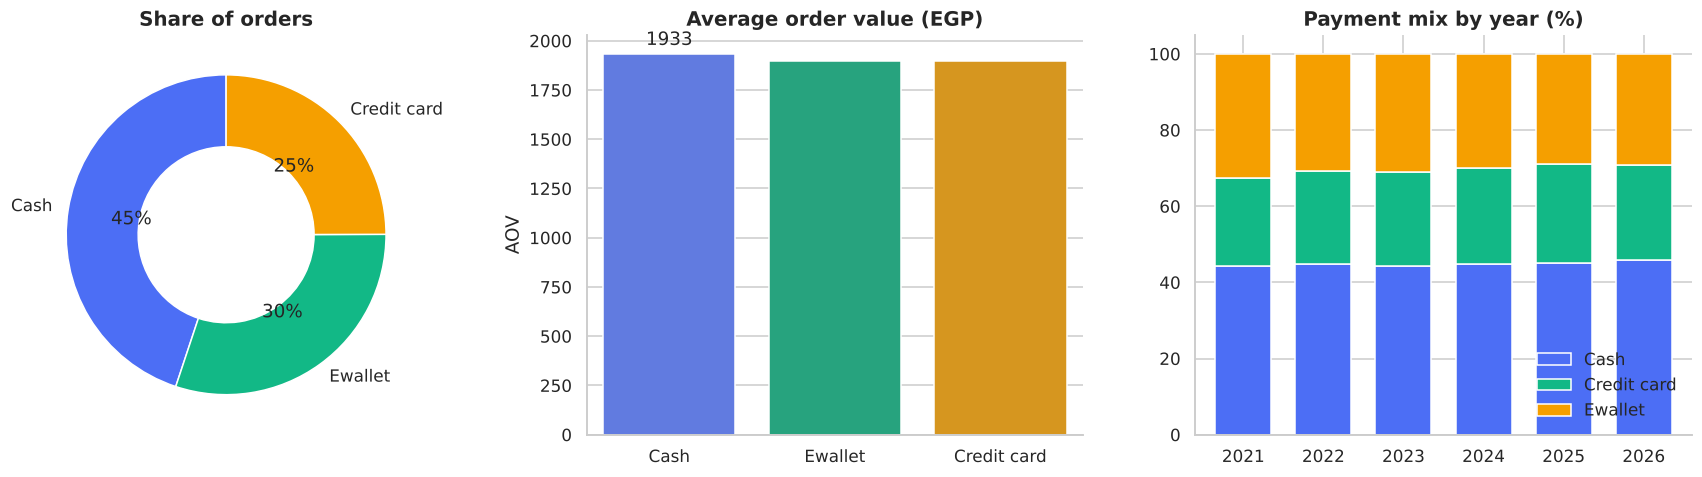

In [8]:
pay = df.groupby("Payment").agg(Revenue=("Total","sum"), Orders=("Order No","count"), AOV=("Total","mean")).sort_values("Revenue", ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].pie(pay.Orders, labels=pay.index, autopct="%1.0f%%", colors=PALETTE, startangle=90, wedgeprops=dict(width=.45, edgecolor="white"))
ax[0].set_title("Share of orders")
sns.barplot(x=pay.index, y=pay.AOV, ax=ax[1], palette=PALETTE); ax[1].set_title("Average order value (EGP)"); ax[1].set_xlabel("")
ax[1].bar_label(ax[1].containers[0], fmt="%.0f", padding=3)
py = df.pivot_table(index="Year", columns="Payment", values="Order No", aggfunc="count")
(py.div(py.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=ax[2], color=PALETTE, rot=0, width=.7)
ax[2].set_title("Payment mix by year (%)"); ax[2].set_xlabel(""); ax[2].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 7 · Time patterns — when do customers buy?

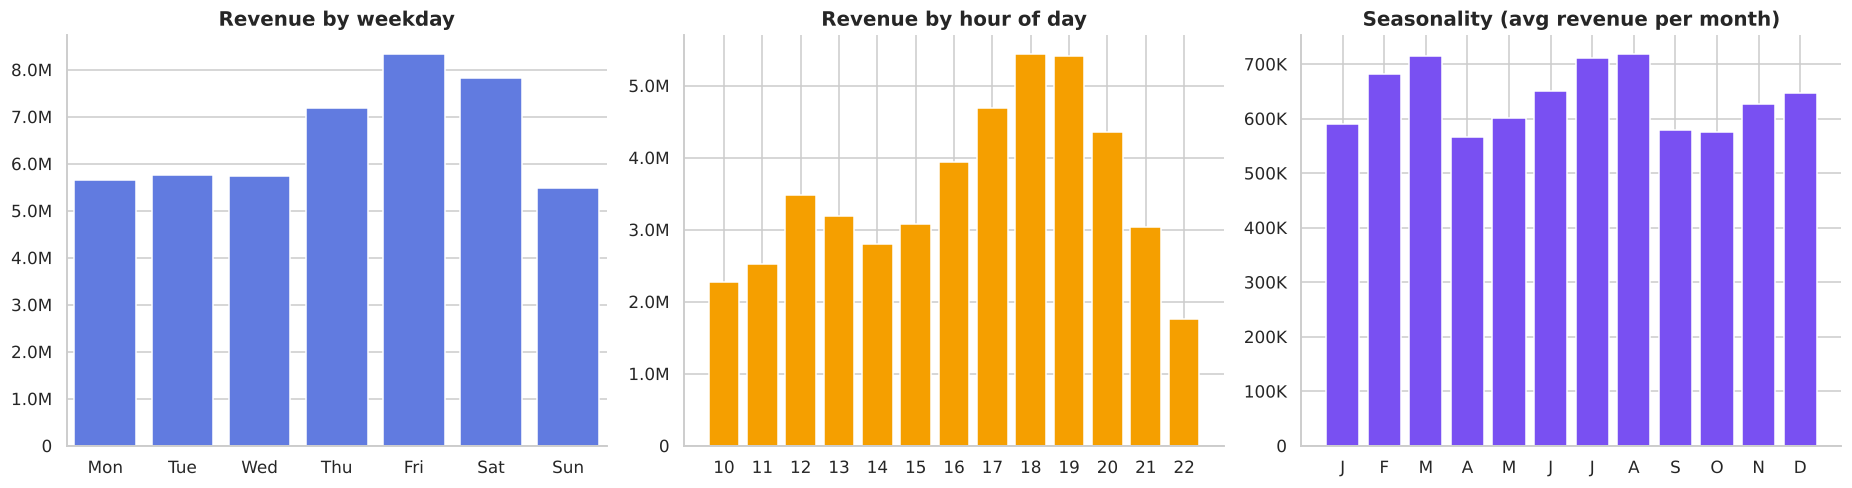

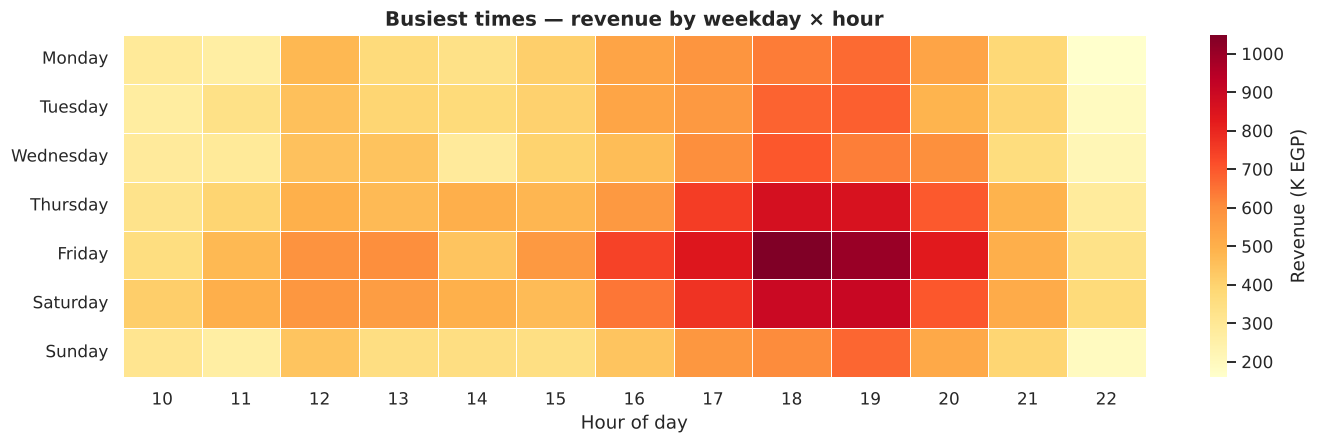

In [9]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
wd = df.groupby("Weekday")["Total"].sum().reindex(order)
sns.barplot(x=wd.index.str[:3], y=wd.values, ax=ax[0], palette=[PALETTE[0]]*7); ax[0].yaxis.set_major_formatter(money); ax[0].set_title("Revenue by weekday"); ax[0].set_xlabel("")
hr = df.groupby("Hour")["Total"].sum()
ax[1].bar(hr.index, hr.values, color=PALETTE[2]); ax[1].yaxis.set_major_formatter(money); ax[1].set_title("Revenue by hour of day"); ax[1].set_xticks(hr.index)
ms = df.groupby("MonthNum")["Total"].sum() / df.Year.nunique()
ax[2].bar(ms.index, ms.values, color=PALETTE[4]); ax[2].yaxis.set_major_formatter(money)
ax[2].set_xticks(range(1, 13)); ax[2].set_xticklabels(["J","F","M","A","M","J","J","A","S","O","N","D"]); ax[2].set_title("Seasonality (avg revenue per month)")
plt.tight_layout(); plt.show()

heat = df.pivot_table(index="Weekday", columns="Hour", values="Total", aggfunc="sum").reindex(order)
plt.figure(figsize=(13, 4.2))
sns.heatmap(heat / 1e3, cmap="YlOrRd", linewidths=.5, cbar_kws={"label": "Revenue (K EGP)"})
plt.title("Busiest times — revenue by weekday × hour"); plt.xlabel("Hour of day"); plt.ylabel(""); plt.tight_layout(); plt.show()

## 8 · Customer satisfaction (ratings)

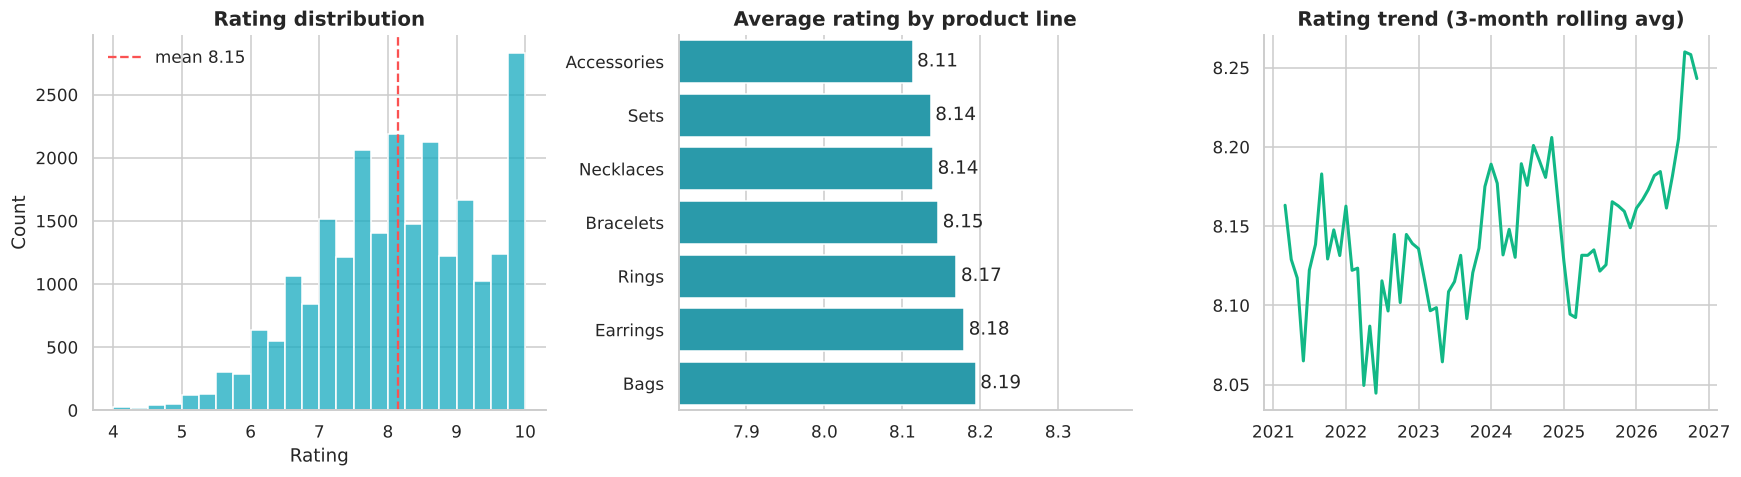

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df.Rating, bins=24, ax=ax[0], color=PALETTE[5]); ax[0].axvline(df.Rating.mean(), color=PALETTE[3], ls="--", label=f"mean {df.Rating.mean():.2f}")
ax[0].legend(frameon=False); ax[0].set_title("Rating distribution")
r = df.groupby("Product Line").Rating.mean().sort_values()
sns.barplot(x=r.values, y=r.index, ax=ax[1], color=PALETTE[5]); ax[1].set_xlim(r.min() - .3, r.max() + .2); ax[1].set_title("Average rating by product line"); ax[1].set_ylabel("")
ax[1].bar_label(ax[1].containers[0], fmt="%.2f", padding=3)
ry = df.groupby("YearMonth").Rating.mean().rolling(3).mean()
ax[2].plot(ry.index, ry.values, color=PALETTE[1], lw=2); ax[2].set_title("Rating trend (3-month rolling avg)")
plt.tight_layout(); plt.show()

## 9 · Inventory

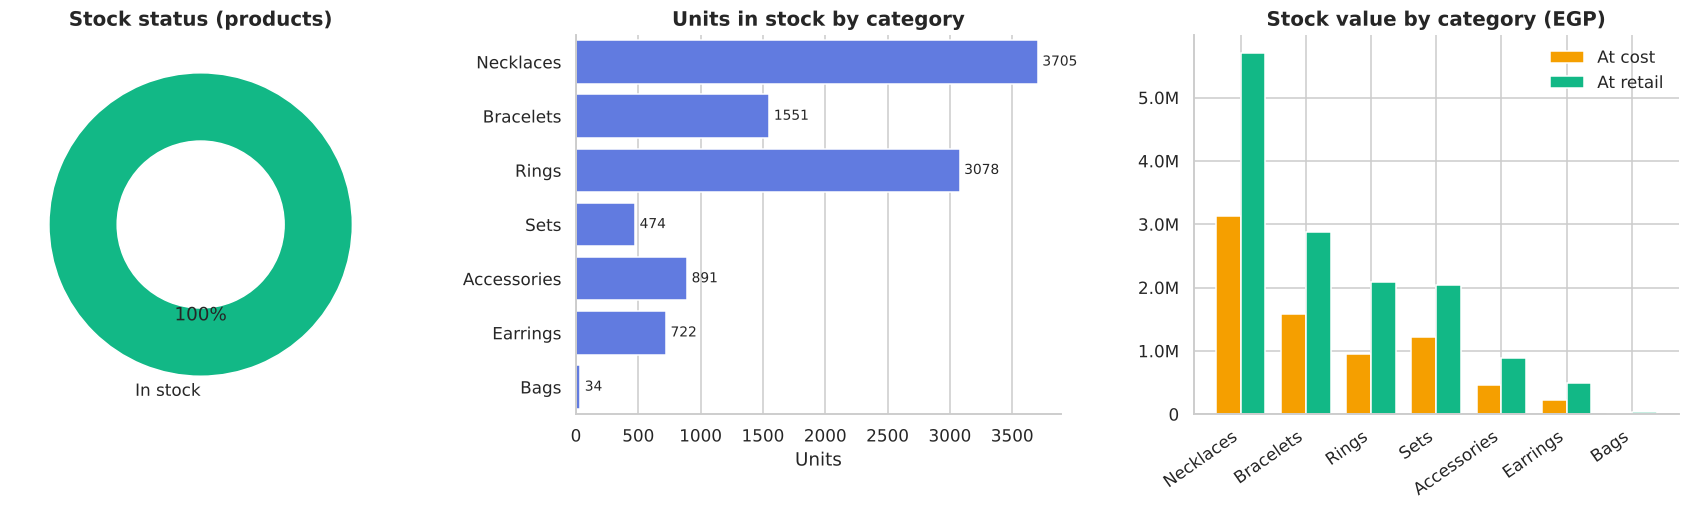

,Units,Cost,Retail
category,,,
Necklaces,"3,705","3,130,448","5,705,700"
Bracelets,"1,551","1,577,656","2,884,860"
Rings,"3,078","956,537","2,093,040"
Sets,474,"1,224,520","2,047,680"
Accessories,891,"460,396","891,000"
Earrings,722,"223,462","490,960"
Bags,34,"19,311","30,600"


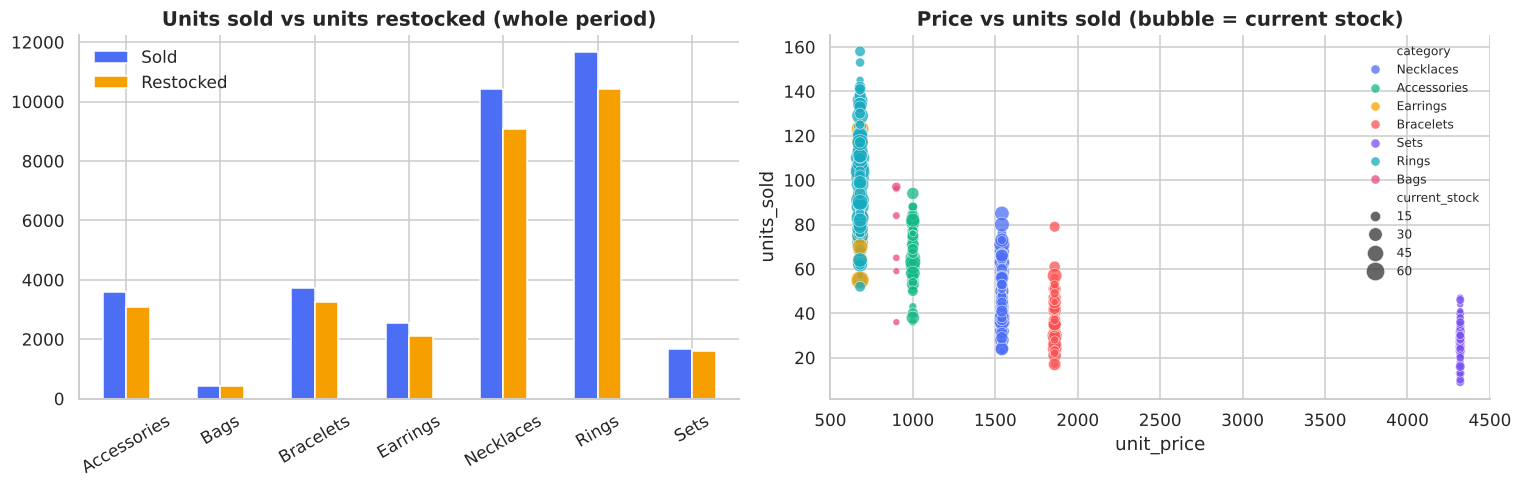

product_id,product_name,category,units_sold,current_stock,stock_value_cost
P0328,Purple Jewelry Set,Sets,9,9,"23,201"
P0401,White Jewelry Set,Sets,10,8,"21,421"
P0391,Black Infinity Jewelry Set,Sets,12,6,"15,197"
P0106,Rose Gold Jewelry Set,Sets,13,11,"27,481"
P0403,Green Clover Jewelry Set,Sets,13,7,"17,293"
P0378,Silver Chain Link Jewelry Set,Sets,15,5,"13,094"
P0527,Rose Gold Infinity Jewelry Set,Sets,16,12,"28,728"
P0157,White Jewelry Set,Sets,16,8,"21,492"
P0457,Gold Initial Letter Jewelry Set,Sets,16,4,"9,539"
P0518,Rose Gold Star Bracelet,Bracelets,17,25,"24,446"


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
st = inv.status.value_counts()
ax[0].pie(st, labels=st.index, autopct="%1.0f%%", colors=[PALETTE[1], PALETTE[3], PALETTE[2]][:len(st)], startangle=90, wedgeprops=dict(width=.45, edgecolor="white"))
ax[0].set_title("Stock status (products)")
cs = inv.groupby("category").agg(Units=("current_stock","sum"), Cost=("stock_value_cost","sum"), Retail=("stock_value_retail","sum")).sort_values("Retail", ascending=False)
sns.barplot(x=cs.Units, y=cs.index, ax=ax[1], color=PALETTE[0]); ax[1].set_title("Units in stock by category"); ax[1].set_ylabel("")
ax[1].bar_label(ax[1].containers[0], fmt="%.0f", padding=3, fontsize=9)
x = np.arange(len(cs)); w = .38
ax[2].bar(x - w/2, cs.Cost, w, label="At cost", color=PALETTE[2]); ax[2].bar(x + w/2, cs.Retail, w, label="At retail", color=PALETTE[1])
ax[2].set_xticks(x); ax[2].set_xticklabels(cs.index, rotation=35, ha="right"); ax[2].yaxis.set_major_formatter(money)
ax[2].set_title("Stock value by category (EGP)"); ax[2].legend(frameon=False)
plt.tight_layout(); plt.show()
display(cs.style.format({"Units":"{:,}","Cost":"{:,.0f}","Retail":"{:,.0f}"}))

# ---- stock health ----
inv["sell_through_%"] = inv.units_sold / (inv.initial_stock + inv.total_restocked) * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
tr = inv.groupby("category").agg(Sold=("units_sold","sum"), Restocked=("total_restocked","sum"))
tr.plot.bar(ax=ax[0], color=[PALETTE[0], PALETTE[2]], rot=30); ax[0].set_title("Units sold vs units restocked (whole period)"); ax[0].set_xlabel("")
ax[0].legend(frameon=False)
sns.scatterplot(data=inv, x="unit_price", y="units_sold", hue="category", size="current_stock", sizes=(20, 160), alpha=.75, ax=ax[1], palette=PALETTE)
ax[1].set_title("Price vs units sold (bubble = current stock)"); ax[1].legend(frameon=False, fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

display(HTML("<b>⚠️ Low-stock products — reorder soon</b>"))
low = inv[inv.status != "In stock"].sort_values("current_stock")
display(low[["product_id","product_name","category","current_stock","reorder_level","units_sold"]].head(15).style.hide(axis="index")
        if len(low) else HTML("<i>No low-stock products 🎉</i>"))

display(HTML("<b>🐌 Slowest movers — most unsold stock tied up in the shelf</b>"))
slow = inv.assign(stock_cost=inv.stock_value_cost).sort_values(["units_sold","stock_cost"], ascending=[True, False]).head(10)
display(slow[["product_id","product_name","category","units_sold","current_stock","stock_value_cost"]].style.format({"stock_value_cost":"{:,.0f}"}).hide(axis="index"))

## 10 · Key insights (auto-generated)

In [12]:
best_line   = pl.Revenue.idxmax();            best_margin = pl["Margin %"].idxmax()
best_year   = yearly.Revenue.idxmax();        last_growth = yearly["Growth %"].dropna().iloc[-1] if yearly["Growth %"].notna().any() else float("nan")
best_day    = wd.idxmax();                    best_hour   = hr.idxmax()
best_month  = pd.Timestamp(2000, int(ms.idxmax()), 1).strftime("%B")
top_pay     = pay.Orders.idxmax();            top_gender  = g.Orders.idxmax()

insights = [
    f"<b>{best_line}</b> is the #1 product line: {pl.Revenue.max()/revenue:.0%} of revenue.",
    f"<b>{best_margin}</b> has the best gross margin ({pl['Margin %'].max():.0f}%).",
    f"Revenue peaked in <b>{best_year}</b> ({yearly.Revenue.max()/1e6:.1f}M EGP); latest year-over-year change: <b>{last_growth:+.0f}%</b> (partial year if the data stops mid-year).",
    f"Busiest weekday: <b>{best_day}</b>; busiest hour: <b>{best_hour}:00</b>; strongest month: <b>{best_month}</b>.",
    f"Most customers are <b>{top_gender.lower()}</b> ({g.Orders.max()/g.Orders.sum():.0%} of orders); most popular payment: <b>{top_pay}</b> ({pay.Orders.max()/pay.Orders.sum():.0%}).",
    f"Only <b>{n80}</b> of {len(p)} products ({n80/len(p):.0%}) produce 80% of revenue — focus stock and promotion on them.",
    f"<b>{(inv.status != 'In stock').sum()}</b> products are at or below their reorder level; <b>{(inv.units_sold == 0).sum()}</b> never sold.",
    f"Average rating is <b>{df.Rating.mean():.1f}/10</b>.",
]
display(HTML('<div style="font-family:Arial;background:#f8f9fa;border-radius:10px;padding:14px 22px;line-height:1.8"><h3 style="margin:0 0 6px">📌 What the data says</h3><ul>'
             + "".join(f"<li>{i}</li>" for i in insights) + "</ul></div>"))